In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [3]:
setwd("/home/liuxuan/metadata/10-10/PRJNA734980/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,analyte_type,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,biospecimen_repository,biospecimen_repository_sample_id,body_site,⋯,create_date,version,Sample.Name,sex,SRA.Study,study_design,study_name,subject_is_affected,submitted_subject_id,study_disease
,<chr>,<chr>,<chr>,<int>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,SRR34790937,DNA,WGS,300,16792620000,PRJNA734981,SAMN49557961,NCI_OralMicrobiome_PancreaticCancer,FCH275KCCXY_L3_CHKSEI85217040047,Oral wash,⋯,2025-08-02T01:23:00Z,1,FCH275KCCXY_L3_CHKSEI85217040047,female,SRP604847,Case-Control,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,No,BWHS_4_5C,
2,SRR34790938,DNA,WGS,300,10464650700,PRJNA734981,SAMN49557968,NCI_OralMicrobiome_PancreaticCancer,FCHLJTJCCXY_L4_WHRDHUMqpfMANSAA-709509,Oral wash,⋯,2025-08-02T01:19:00Z,1,FCHLJTJCCXY_L4_WHRDHUMqpfMANSAA-709509,female,SRP604847,Case-Control,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,No,BWHS_3_4F,
3,SRR34790939,DNA,WGS,300,8610198300,PRJNA734981,SAMN49558490,NCI_OralMicrobiome_PancreaticCancer,FCHLMVLCCXY_L4_WHRDHUMqpfMAKTAA-704511,Oral wash,⋯,2025-08-02T01:18:00Z,1,FCHLMVLCCXY_L4_WHRDHUMqpfMAKTAA-704511,female,SRP604847,Case-Control,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,No,M021176,
4,SRR34790940,DNA,WGS,300,13727741400,PRJNA734981,SAMN49558415,NCI_OralMicrobiome_PancreaticCancer,FCHLMVLCCXY_L6_WHRDHUMqpfMALUAA-707503,Oral wash,⋯,2025-08-02T01:21:00Z,1,FCHLMVLCCXY_L6_WHRDHUMqpfMALUAA-707503,male,SRP604847,Case-Control,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,No,SCCS_1_97,
5,SRR34790941,DNA,WGS,300,9569232900,PRJNA734981,SAMN49558210,NCI_OralMicrobiome_PancreaticCancer,FCHLNMVCCXY_L7_WHRDHUMqpfMAQLAA-710509,Oral wash,⋯,2025-08-02T01:19:00Z,1,FCHLNMVCCXY_L7_WHRDHUMqpfMAQLAA-710509,female,SRP604847,Case-Control,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,No,M037743,
6,SRR34790942,DNA,WGS,300,10000929000,PRJNA734981,SAMN49557788,NCI_OralMicrobiome_PancreaticCancer,FCHLNMWCCXY_L6_WHRDHUMqpfMAICAA-707503,Oral wash,⋯,2025-08-02T01:19:00Z,1,FCHLNMWCCXY_L6_WHRDHUMqpfMAICAA-707503,male,SRP604847,Case-Control,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,No,SCCS_5_75,


[1] "Run"                              "analyte_type"                    
 [3] "Assay.Type"                       "AvgSpotLen"                      
 [5] "Bases"                            "BioProject"                      
 [7] "BioSample"                        "biospecimen_repository"          
 [9] "biospecimen_repository_sample_id" "body_site"                       
[11] "Bytes"                            "Center.Name"                     
[13] "Consent.code"                     "Consent"                         
[15] "DATASTORE.filetype"               "DATASTORE.provider"              
[17] "DATASTORE.region"                 "Experiment"                      
[19] "dbGaP.accession"                  "Instrument"                      
[21] "is_tumor"                         "Library.Name"                    
[23] "LibraryLayout"                    "LibrarySelection"                
[25] "LibrarySource"                    "Organism"                        
[27] "Platform"                         "ReleaseDate"                     
[29] "create_date"                      "version"                         
[31] "Sample.Name"                      "sex"                             
[33] "SRA.Study"                        "study_design"                    
[35] "study_name"                       "subject_is_affected"             
[37] "submitted_subject_id"             "study_disease"

In [4]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'submitted_subject_id',
    Age = NA,
    BMI = NA,
    Sex = initial_meta$sex,
    Region = NA,
    Platform = initial_meta$Platform,
    Country = NA,
    Site = NA,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = "A Prospective Study of the Oral Microbiome and Pancreatic Cancer",
    Disease_study = "YES",
    Status = initial_meta$'study_disease',
    matched_samples = 'NO')

In [5]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 757
[1] 674


In [6]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<chr>,<lgl>,<chr>,<lgl>,<lgl>,<chr>,<lgl>,<chr>,<chr>,<chr>,<chr>
1,PRJNA734981,SRR34790937,BWHS_4_5C,NA,NA,female,NA,ILLUMINA,NA,NA,2025-08-08T00:00:00Z,NA,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,YES,,NO
2,PRJNA734981,SRR34790938,BWHS_3_4F,NA,NA,female,NA,ILLUMINA,NA,NA,2025-08-08T00:00:00Z,NA,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,YES,,NO
3,PRJNA734981,SRR34790939,M021176,NA,NA,female,NA,ILLUMINA,NA,NA,2025-08-08T00:00:00Z,NA,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,YES,,NO
4,PRJNA734981,SRR34790940,SCCS_1_97,NA,NA,male,NA,ILLUMINA,NA,NA,2025-08-08T00:00:00Z,NA,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,YES,,NO
5,PRJNA734981,SRR34790941,M037743,NA,NA,female,NA,ILLUMINA,NA,NA,2025-08-08T00:00:00Z,NA,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,YES,,NO
6,PRJNA734981,SRR34790942,SCCS_5_75,NA,NA,male,NA,ILLUMINA,NA,NA,2025-08-08T00:00:00Z,NA,A Prospective Study of the Oral Microbiome and Pancreatic Cancer,YES,,NO


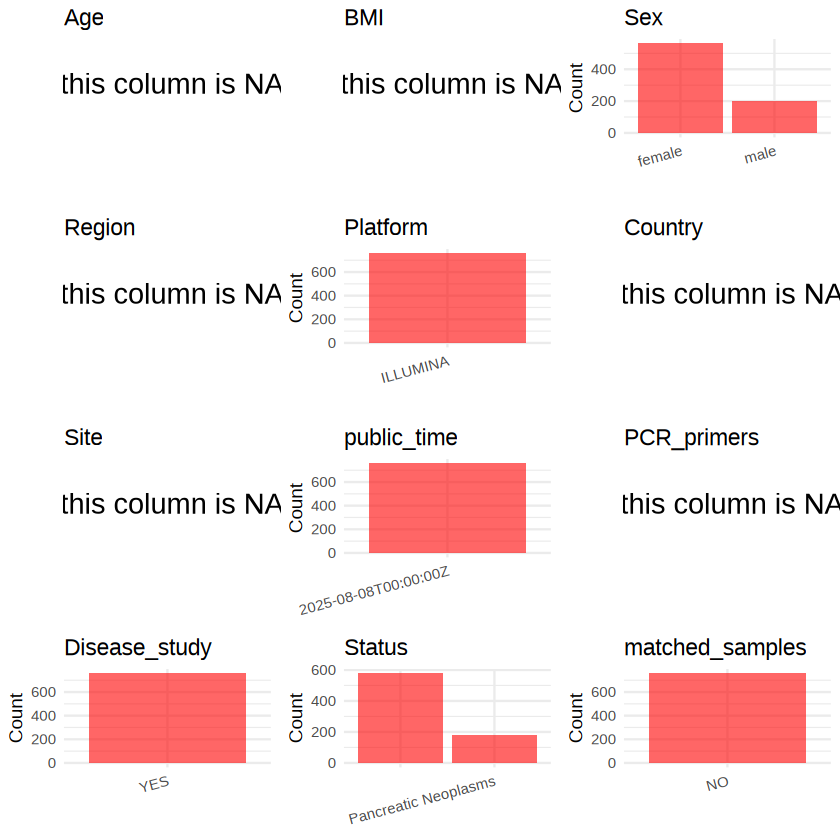

In [7]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [8]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJNA734980/metadata.csv", quote = T)